In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import datetime as dt

import seaborn as sns
from sklearn import model_selection

In [2]:
df = pd.read_csv(r"data/transactions.csv")
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,transaction_time,shipping_distance_km,is_fraud
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,2024-01-06T04:09:39Z,370.95,0
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,2024-01-09T20:13:47Z,149.62,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,2024-01-12T06:20:11Z,164.08,0
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,2024-01-15T17:00:04Z,397.40,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,2024-01-17T01:27:31Z,935.28,0


**Sample**
-

In [3]:
df.shape

(299695, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  str    
 7   bin_country              299695 non-null  str    
 8   channel                  299695 non-null  str    
 9   merchant_category        299695 non-null  str    
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  transaction_tim

In [5]:
print("Duplicated lines: ",df.duplicated().sum())
print("Duplicated transactions ids: ",df['transaction_id'].duplicated().sum())

Duplicated lines:  0
Duplicated transactions ids:  0


In [6]:
df['transaction_time'].sort_values().unique()

<ArrowStringArray>
['2024-01-01T00:04:37Z', '2024-01-01T00:06:18Z', '2024-01-01T00:10:27Z',
 '2024-01-01T00:11:09Z', '2024-01-01T00:12:24Z', '2024-01-01T00:12:29Z',
 '2024-01-01T00:13:14Z', '2024-01-01T00:13:45Z', '2024-01-01T00:15:31Z',
 '2024-01-01T00:17:49Z',
 ...
 '2024-10-31T23:49:05Z', '2024-10-31T23:49:06Z', '2024-10-31T23:49:15Z',
 '2024-10-31T23:49:32Z', '2024-10-31T23:49:37Z', '2024-10-31T23:51:57Z',
 '2024-10-31T23:55:29Z', '2024-10-31T23:55:45Z', '2024-10-31T23:56:54Z',
 '2024-10-31T23:58:19Z']
Length: 297975, dtype: str

Tratando coluna com data e hora

In [7]:
df['transaction_datetime'] = df.transaction_time
df['transaction_datetime'] = pd.to_datetime(df['transaction_datetime'])
df.drop(['transaction_time'], axis=1, inplace=True)
df['transaction_date'] = df['transaction_datetime'].dt.date
df['transaction_hour'] = df['transaction_datetime'].dt.hour

df['transaction_month'] = df['transaction_datetime'].dt.month #helpful to check stability overtime, for oot split

df['week_day'] = df['transaction_datetime'].dt.dayofweek #first day of week: monday(0)
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,...,avs_match,cvv_result,three_ds_flag,shipping_distance_km,is_fraud,transaction_datetime,transaction_date,transaction_hour,transaction_month,week_day
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,...,1,1,1,370.95,0,2024-01-06 04:09:39+00:00,2024-01-06,4,1,5
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,...,0,0,0,149.62,0,2024-01-09 20:13:47+00:00,2024-01-09,20,1,1
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,...,1,1,1,164.08,0,2024-01-12 06:20:11+00:00,2024-01-12,6,1,4
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,...,1,1,1,397.40,0,2024-01-15 17:00:04+00:00,2024-01-15,17,1,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,...,1,1,1,935.28,0,2024-01-17 01:27:31+00:00,2024-01-17,1,1,2


**Creating feature for difference between bin country and country**

In [8]:
df['diff_country'] = (df['bin_country'] != df['country']).astype(int)

**Creating proportion of amount and avg_amount_user**

In [9]:
df['diff_amount'] = df['amount'] / df['avg_amount_user']

**Creating feature to check if the transaction have security verifications**

In [10]:
df['security_verification_score'] = df['avs_match'] + df['cvv_result'] + df['three_ds_flag']
df.head(15)

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,...,shipping_distance_km,is_fraud,transaction_datetime,transaction_date,transaction_hour,transaction_month,week_day,diff_country,diff_amount,security_verification_score
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,...,370.95,0,2024-01-06 04:09:39+00:00,2024-01-06,4,1,5,0,0.572906,3
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,...,149.62,0,2024-01-09 20:13:47+00:00,2024-01-09,20,1,1,0,0.729399,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,...,164.08,0,2024-01-12 06:20:11+00:00,2024-01-12,6,1,4,0,0.624349,3
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,...,397.40,0,2024-01-15 17:00:04+00:00,2024-01-15,17,1,0,0,0.760292,3
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,...,935.28,0,2024-01-17 01:27:31+00:00,2024-01-17,1,1,2,1,0.898465,3
5,6,1,141,47,147.93,224.82,FR,FR,web,travel,...,289.06,0,2024-01-26 22:05:08+00:00,2024-01-26,22,1,4,0,1.519773,3
6,7,1,141,47,147.93,125.98,FR,FR,app,electronics,...,443.75,0,2024-01-30 00:51:41+00:00,2024-01-30,0,1,1,0,0.851619,3
7,8,1,141,47,147.93,66.95,FR,RO,web,travel,...,1390.59,0,2024-02-11 15:33:30+00:00,2024-02-11,15,2,6,1,0.452579,3
8,9,1,141,47,147.93,261.58,FR,FR,app,grocery,...,110.51,0,2024-02-22 01:29:55+00:00,2024-02-22,1,2,3,0,1.768269,0
9,10,1,141,47,147.93,97.34,FR,FR,web,electronics,...,232.34,0,2024-03-09 11:13:19+00:00,2024-03-09,11,3,5,0,0.658014,2


In [11]:
df.head()

,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,...,shipping_distance_km,is_fraud,transaction_datetime,transaction_date,transaction_hour,transaction_month,week_day,diff_country,diff_amount,security_verification_score
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,...,370.95,0,2024-01-06 04:09:39+00:00,2024-01-06,4,1,5,0,0.572906,3
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,...,149.62,0,2024-01-09 20:13:47+00:00,2024-01-09,20,1,1,0,0.729399,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,...,164.08,0,2024-01-12 06:20:11+00:00,2024-01-12,6,1,4,0,0.624349,3
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,...,397.40,0,2024-01-15 17:00:04+00:00,2024-01-15,17,1,0,0,0.760292,3
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,...,935.28,0,2024-01-17 01:27:31+00:00,2024-01-17,1,1,2,1,0.898465,3


**Creating OOT**

Nearly 10% of dataset for validation. We need to investigate if all months have the same rate of frauds, so we don't create an oot of a peculiar harvest.

,qtd,fraud_rate
transaction_month,,
1,30605,0.021728
2,28586,0.022773
3,30159,0.022448
4,29323,0.021792
5,30534,0.022336
6,29691,0.022903
7,30213,0.021481
8,30390,0.021356
9,29833,0.021721


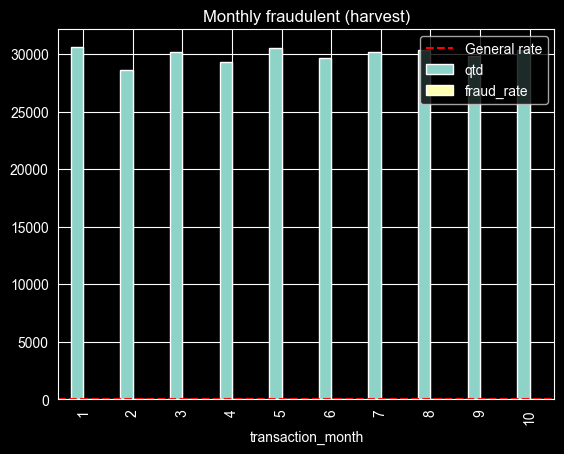

In [12]:
monthly = df.groupby('transaction_month')['is_fraud'].agg(qtd='count', fraud_rate= 'mean')
monthly.plot(kind='bar', title='Monthly fraudulent (harvest)')
plt.axhline(y=df['is_fraud'].mean(), color="red", linestyle='--', label='General rate')
plt.legend()
monthly

In [13]:
df = df.drop('transaction_month', axis=1)

In [14]:
df['transaction_date'].max()

datetime.date(2024, 10, 31)

In [15]:
cutoff = dt.date(2024, 10, 28)

oot = df[df['transaction_date'] > cutoff]
df_train = df[df['transaction_date'] <= cutoff]

print(f'OOT: {len(oot)} transactions ({len(oot) / len(df):.1%} of transactions)')
print(f'Train: {len(df_train)} transactions ({len(df_train) / len(df):.1%} of transactions)')
print(f'Fraud rate in train: {df_train.is_fraud.mean():.2%}')
print(f'Fraud rate in OOT: {oot.is_fraud.mean():.2%}')

OOT: 2964 transactions (1.0% of transactions)
Train: 296731 transactions (99.0% of transactions)
Fraud rate in train: 2.20%
Fraud rate in OOT: 2.73%


Spliting features and target. Dropping non feature or useless columns

In [16]:
features = df_train.columns.drop(['is_fraud','transaction_id','user_id','transaction_datetime', 'transaction_date'])
target = 'is_fraud'
features

Index(['account_age_days', 'total_transactions_user', 'avg_amount_user',
       'amount', 'country', 'bin_country', 'channel', 'merchant_category',
       'promo_used', 'avs_match', 'cvv_result', 'three_ds_flag',
       'shipping_distance_km', 'transaction_hour', 'week_day', 'diff_country',
       'diff_amount', 'security_verification_score'],
      dtype='str')

In [17]:
X, y = df_train[features], df_train[target]
X.head()

,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,transaction_hour,week_day,diff_country,diff_amount,security_verification_score
0,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,370.95,4,5,0,0.572906,3
1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,149.62,20,1,0,0.729399,0
2,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,164.08,6,4,0,0.624349,3
3,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,397.40,17,0,0,0.760292,3
4,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,935.28,1,2,1,0.898465,3


In [18]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: is_fraud, dtype: int64

In [19]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [20]:
print("Shape of train features dataset: ",X_train.shape[0])
print("Shape of train target dataset: ",y_train.shape[0])
print("Shape of test features dataset: ",X_test.shape[0])
print("Shape of test target dataset: ",y_test.shape[0])

Shape of train features dataset:  237384
Shape of train target dataset:  237384
Shape of test features dataset:  59347
Shape of test target dataset:  59347


In [21]:
print('Train period dataset', y.mean())
print('Train fraud rate', y_train.mean())
print('Test fraud rate', y_test.mean())

Train period dataset 0.022009833822553088
Train fraud rate 0.022010750513935227
Test fraud rate 0.022006167118809712


**Explore**
-

In [22]:
X_train.isna().sum().sort_values(ascending=False)

account_age_days               0
total_transactions_user        0
avg_amount_user                0
amount                         0
country                        0
bin_country                    0
channel                        0
merchant_category              0
promo_used                     0
avs_match                      0
cvv_result                     0
three_ds_flag                  0
shipping_distance_km           0
transaction_hour               0
week_day                       0
diff_country                   0
diff_amount                    0
security_verification_score    0
dtype: int64

Creating dataframe with all train columns (features + target)

In [23]:
df_analysis = pd.concat([X_train, y_train], axis=1).copy()
df_analysis['is_fraud'] = pd.to_numeric(df_analysis['is_fraud'])
df_analysis.head()

,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,transaction_hour,week_day,diff_country,diff_amount,security_verification_score,is_fraud
162213,1045,51,259.33,498.39,TR,TR,app,gaming,0,1,1,0,388.29,16,6,0,1.921837,2,0
23514,344,53,19.78,23.36,IT,IT,app,grocery,0,1,1,1,440.89,20,2,0,1.180991,3,0
97883,556,43,119.77,45.90,ES,ES,web,fashion,1,1,1,1,163.22,23,2,0,0.383235,3,0
89375,307,55,343.93,201.40,US,US,web,electronics,1,1,1,1,46.59,9,5,0,0.585584,3,0
233780,1137,50,31.91,46.66,DE,DE,app,grocery,0,1,1,1,361.09,15,2,0,1.462238,3,0


Spliting numerical and categorical features

In [24]:
num_features = X_train.select_dtypes('number').columns.tolist()
cat_features = X_train.select_dtypes("str").columns.tolist()
print("Numerical variables: ", num_features)
print("Categorical variables: ",cat_features)

Numerical variables:  ['account_age_days', 'total_transactions_user', 'avg_amount_user', 'amount', 'promo_used', 'avs_match', 'cvv_result', 'three_ds_flag', 'shipping_distance_km', 'transaction_hour', 'week_day', 'diff_country', 'diff_amount', 'security_verification_score']
Categorical variables:  ['country', 'bin_country', 'channel', 'merchant_category']


In [25]:
binaries_features = ['promo_used','diff_country','avs_match', 'cvv_result', 'three_ds_flag','security_verification_score']
log_features = ['avg_amount_user', 'amount','shipping_distance_km','diff_amount']
time_features = ['week_day', 'transaction_hour']
continuous_features = [f for f in num_features if f not in binaries_features + time_features]
general_rate = df_analysis[target].mean()
continuous_features

['account_age_days',
 'total_transactions_user',
 'avg_amount_user',
 'amount',
 'shipping_distance_km',
 'diff_amount']

In [26]:
df_analysis[num_features].describe()

,account_age_days,total_transactions_user,avg_amount_user,amount,promo_used,avs_match,cvv_result,three_ds_flag,shipping_distance_km,transaction_hour,week_day,diff_country,diff_amount,security_verification_score
count,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000,237384.000000
mean,973.491297,50.673221,147.888686,176.622488,0.153574,0.838174,0.872439,0.784796,356.955198,11.516964,2.981305,0.079028,1.312208,2.495408
std,524.942365,5.972022,199.224210,303.785571,0.360541,0.368292,0.333601,0.410965,427.154721,6.928236,2.005298,0.269783,4.118804,0.866618
min,1.000000,40.000000,3.520000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001276,0.000000
25%,518.000000,46.000000,46.190000,42.080000,0.000000,1.000000,1.000000,1.000000,136.697500,5.000000,1.000000,0.000000,0.714361,2.000000
50%,974.000000,51.000000,90.060000,90.030000,0.000000,1.000000,1.000000,1.000000,272.950000,12.000000,3.000000,0.000000,1.003407,3.000000
75%,1425.000000,56.000000,173.450000,190.872500,0.000000,1.000000,1.000000,1.000000,409.380000,18.000000,5.000000,0.000000,1.408914,3.000000
max,1890.000000,60.000000,4565.290000,16979.920000,1.000000,1.000000,1.000000,1.000000,3748.560000,23.000000,6.000000,1.000000,597.512605,3.000000


In [27]:
for feature in cat_features:
    print(feature)
    print("-"*40)
    print(f"{df_analysis[feature].nunique()} unique values: ")
    percent = (df_analysis[feature].value_counts(normalize=True) * 100)
    print(percent.apply(lambda x:f"{x:.2f}%"))
    print()

country
----------------------------------------
10 unique values: 
country
US    10.79%
GB    10.16%
FR    10.10%
NL    10.06%
TR    10.05%
PL    10.00%
RO     9.84%
DE     9.72%
ES     9.70%
IT     9.58%
Name: proportion, dtype: str

bin_country
----------------------------------------
10 unique values: 
bin_country
US    10.73%
GB    10.16%
FR    10.09%
NL    10.07%
TR    10.02%
PL    10.02%
RO     9.83%
ES     9.74%
DE     9.72%
IT     9.61%
Name: proportion, dtype: str

channel
----------------------------------------
2 unique values: 
channel
web    50.77%
app    49.23%
Name: proportion, dtype: str

merchant_category
----------------------------------------
5 unique values: 
merchant_category
electronics    20.08%
grocery        20.02%
travel         19.98%
gaming         19.97%
fashion        19.95%
Name: proportion, dtype: str



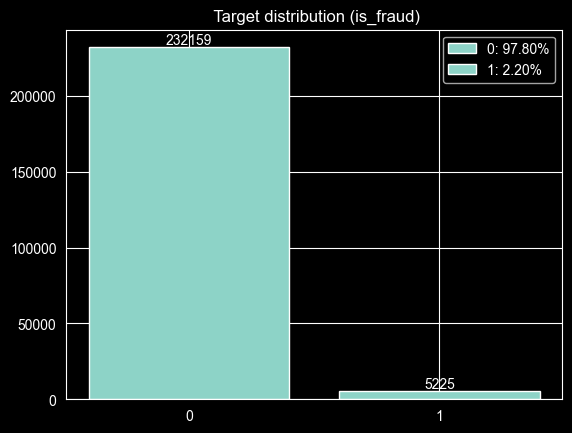

In [28]:
count = df_analysis[target].value_counts()
percent_count = df_analysis[target].value_counts(normalize=True) * 100
legend_labels = [f'{idx}: {percent_count[idx]:.2f}%' for idx in count.index]

plt.title(" Target distribution (is_fraud)")

bars = plt.bar(count.index.astype(str), count.values, align='center')
plt.bar_label(bars)
plt.legend(bars, legend_labels)
plt.show()

The dataset is way disbalanced: just 2.2% of transactions is fraud. So, accuracy doesn't work as a metric, because a model that never predict as fraud would have 97,8% of accuracy. In the modeling, I will prioritize recall, precision and PR-AUC, also maintaining stratified split

**Distribution of numerical features**

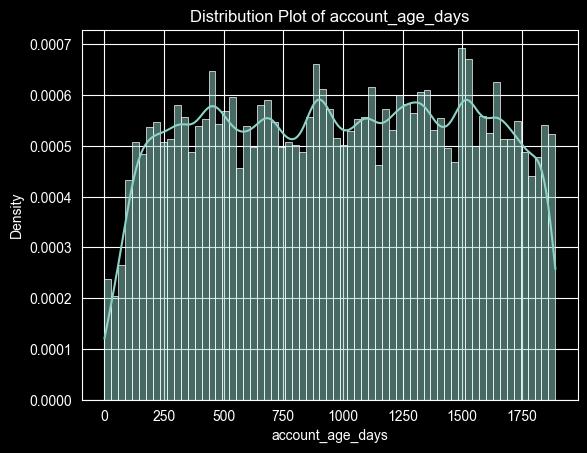

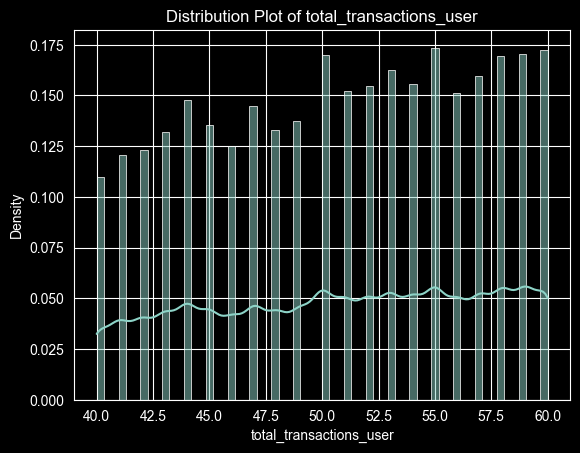

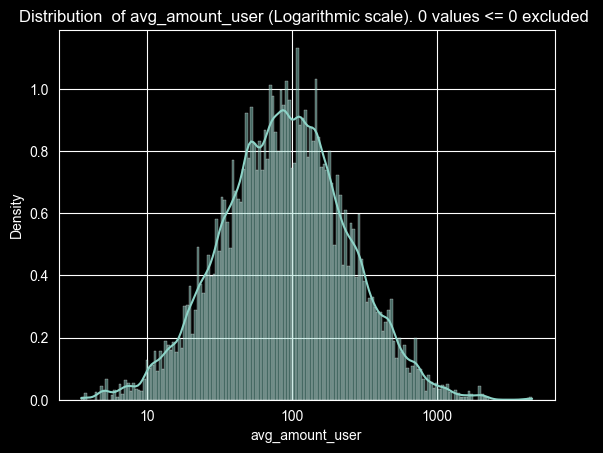

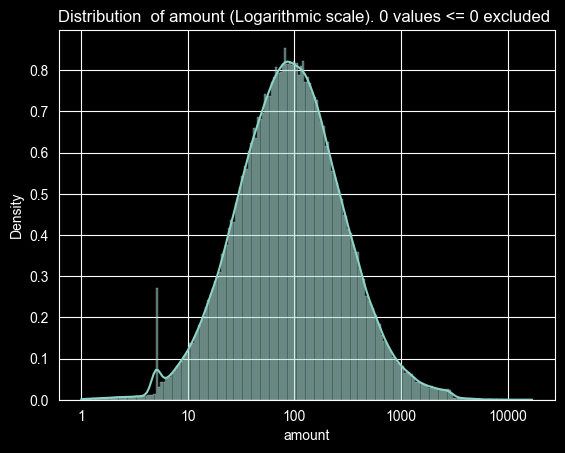

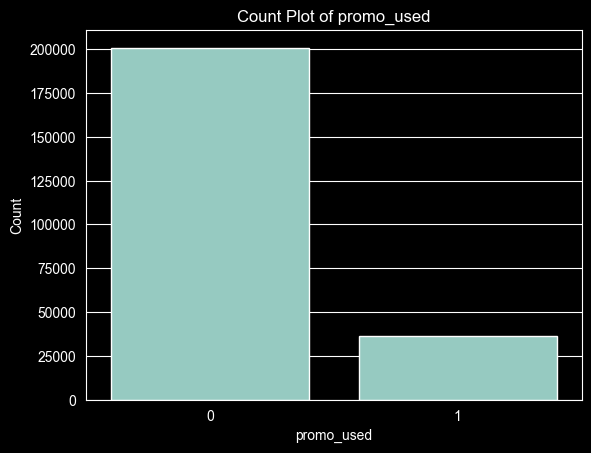

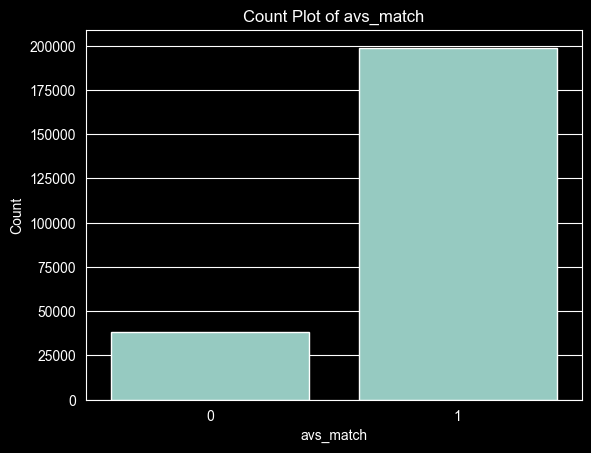

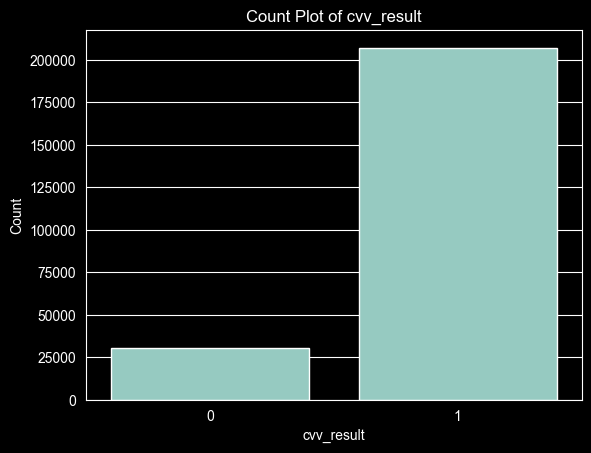

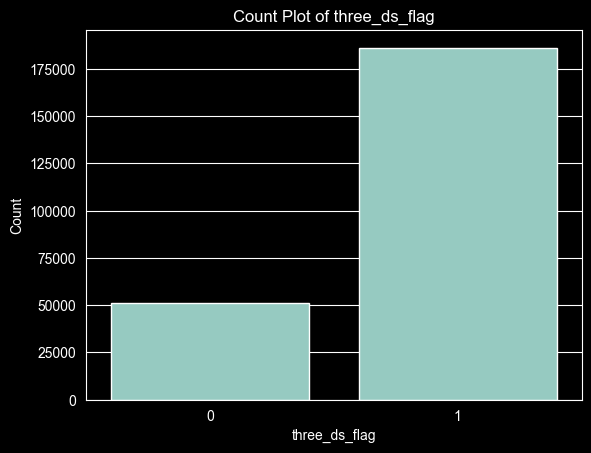

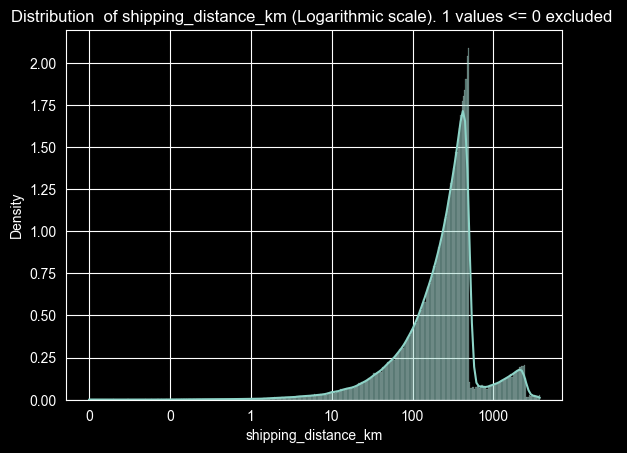

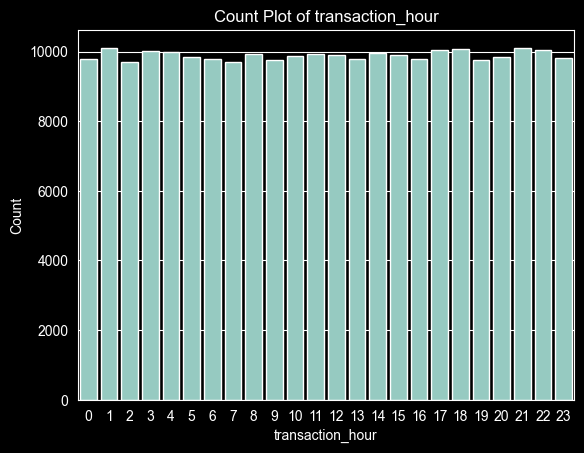

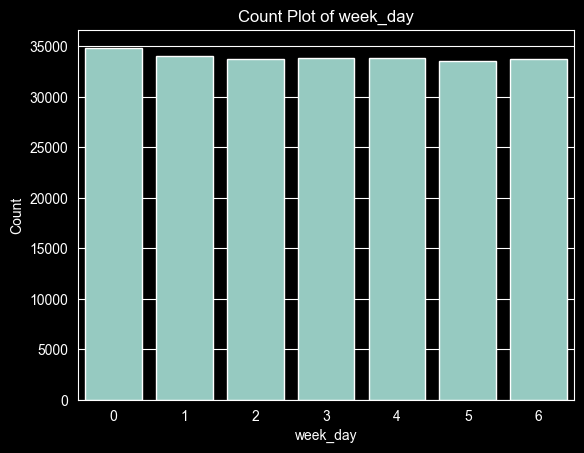

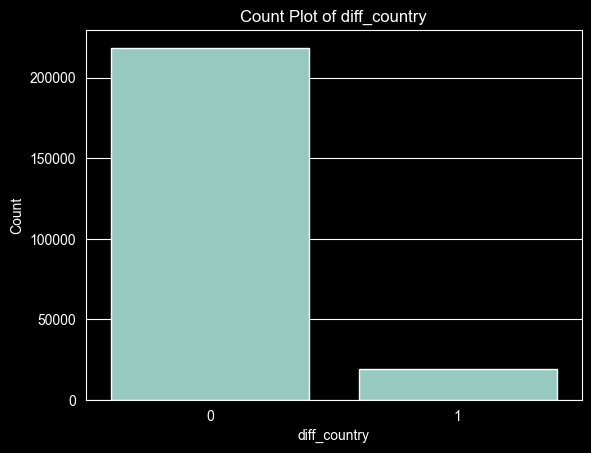

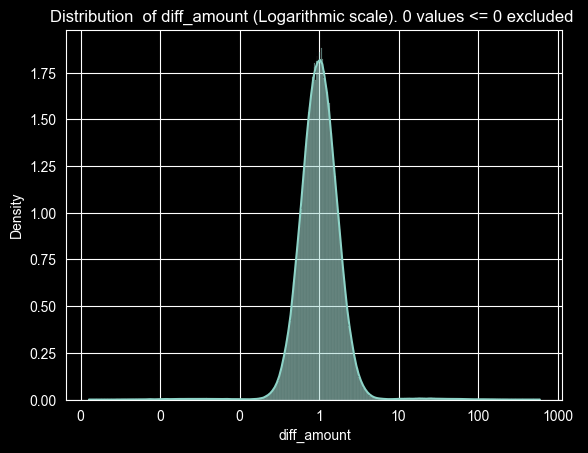

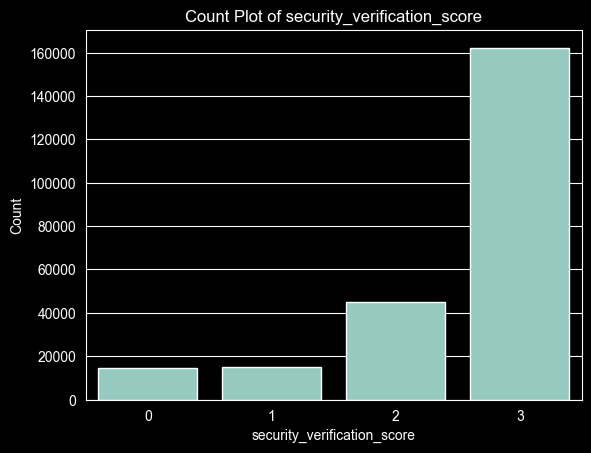

In [29]:
for feature in num_features:
    if feature in log_features:
        data = df_analysis[df_analysis[feature] > 0]
        excluded = (df_analysis[feature] <= 0).sum()
        sns.histplot(data=data, x=feature, kde=True, stat='density', log_scale=True)
        plt.gca().xaxis.set_major_formatter(ticker.ScalarFormatter())
        plt.title(f'Distribution  of {feature} (Logarithmic scale). {excluded} values <= 0 excluded ')
        plt.show()
    elif feature in binaries_features + time_features:
        sns.countplot(data=df_analysis, x=feature)
        plt.ylabel('Count')
        plt.title(f'Count Plot of {feature}')
        plt.show()

    else:
        sns.histplot(data=df_analysis, x=feature, kde=True, stat='density')
        plt.ylabel('Density')
        plt.title(f'Distribution Plot of {feature}')
        plt.show()


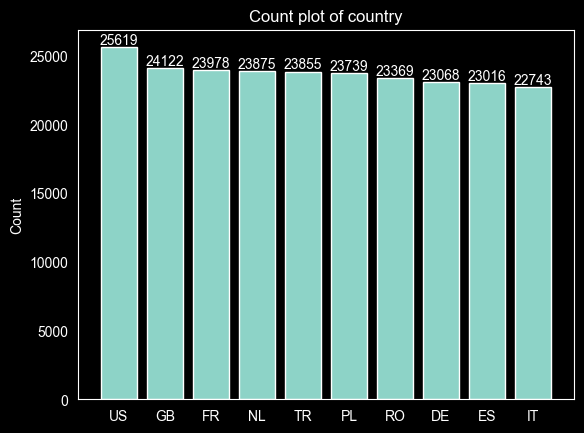

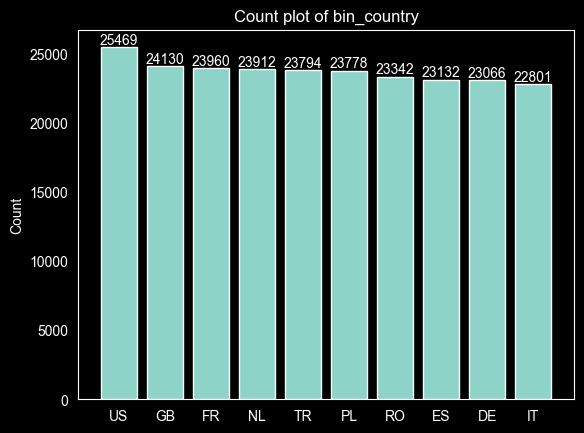

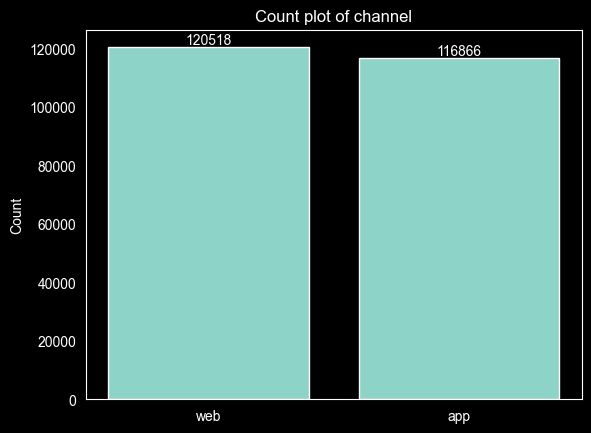

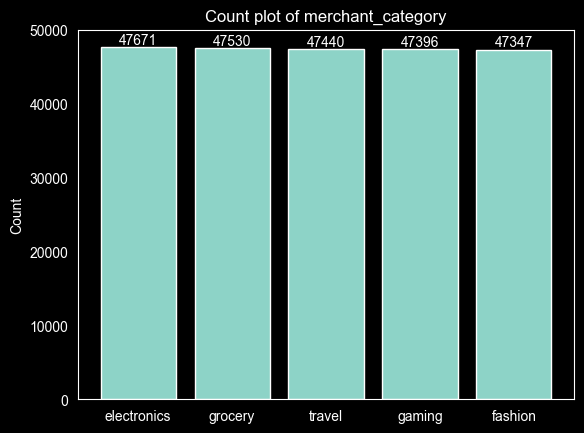

In [30]:
for feature in cat_features:
        count = df_analysis[feature].value_counts()
        bars = plt.bar(count.index.astype(str), count.values, align='center')
        plt.bar_label(bars)
        plt.grid(False)
        plt.ylabel("Count")
        plt.title(f'Count plot of {feature}')
        plt.show()

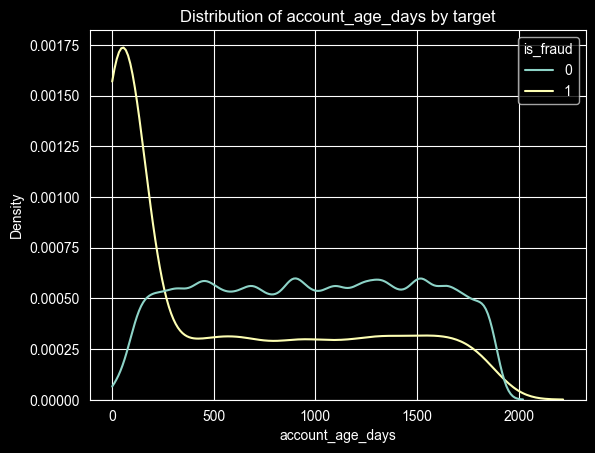

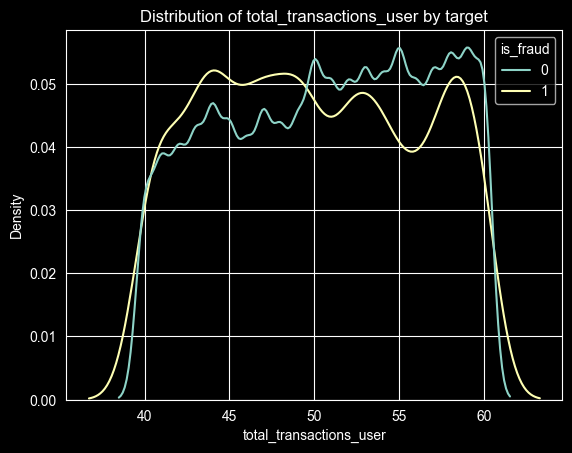

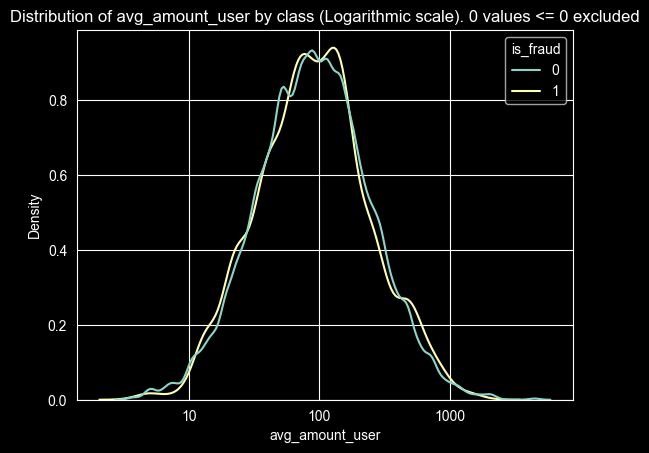

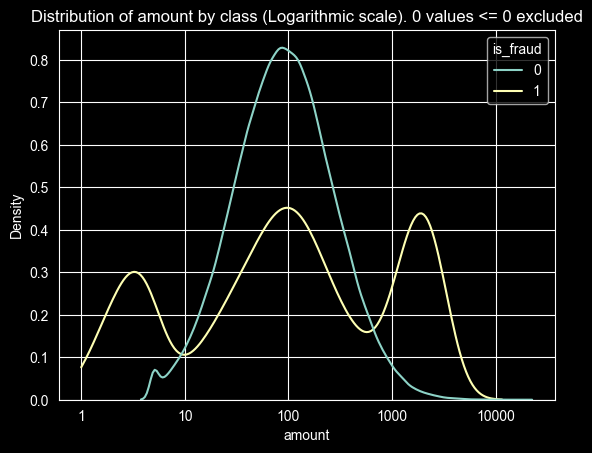

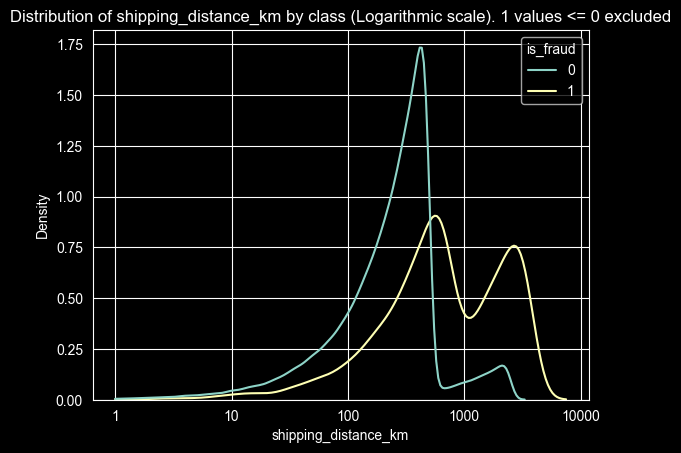

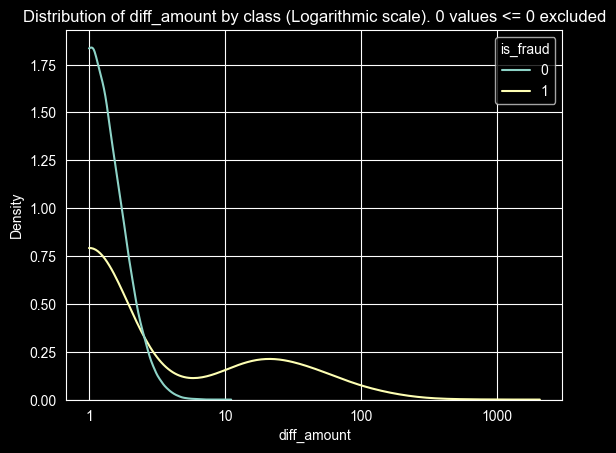

In [31]:
for feature in continuous_features:

    if feature in log_features:
        data = df_analysis[df_analysis[feature] > 0]
        excluded = (df_analysis[feature] <= 0).sum()
        sns.kdeplot(data=data, x=feature, hue=target, common_norm=False, log_scale=True, clip=(0, None))
        plt.gca().xaxis.set_major_formatter(ticker.ScalarFormatter())
        plt.title(f'Distribution of {feature} by class (Logarithmic scale). {excluded} values <= 0 excluded')
    else:
        sns.kdeplot(data=df_analysis, x=feature, hue=target, common_norm=False, clip=(0, None))
        plt.title(f'Distribution of {feature} by target')
    plt.show()

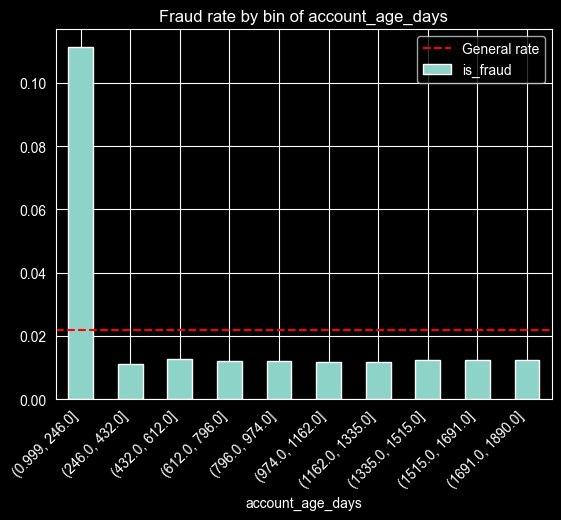

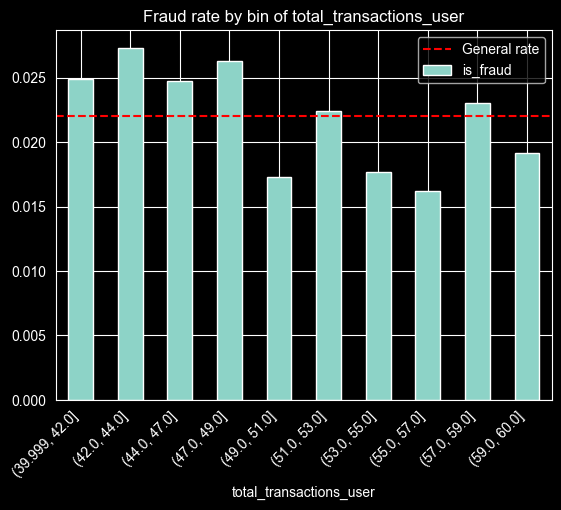

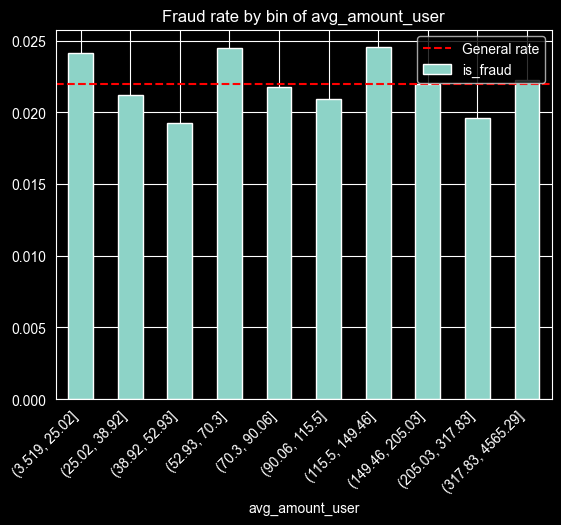

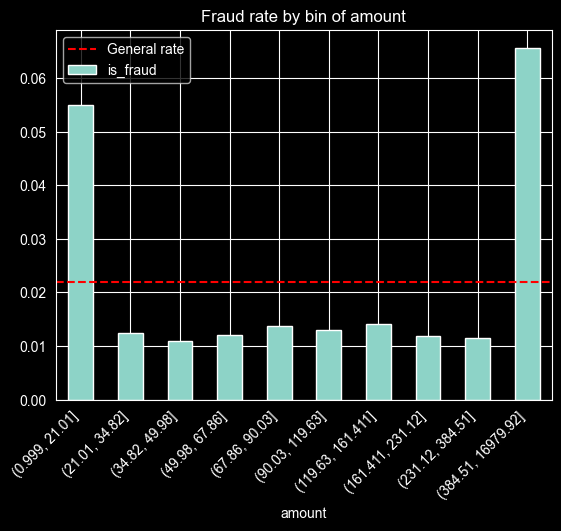

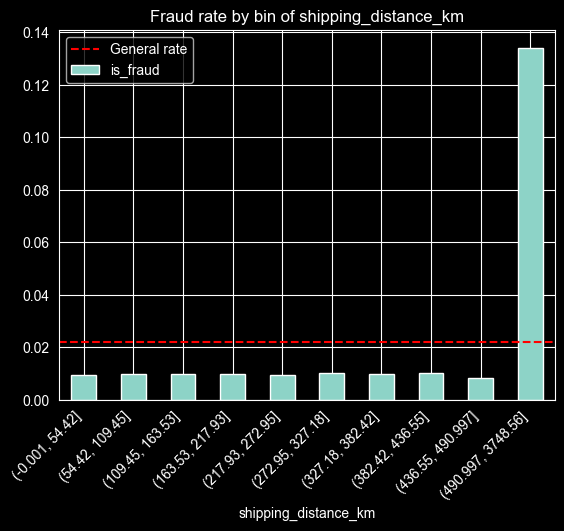

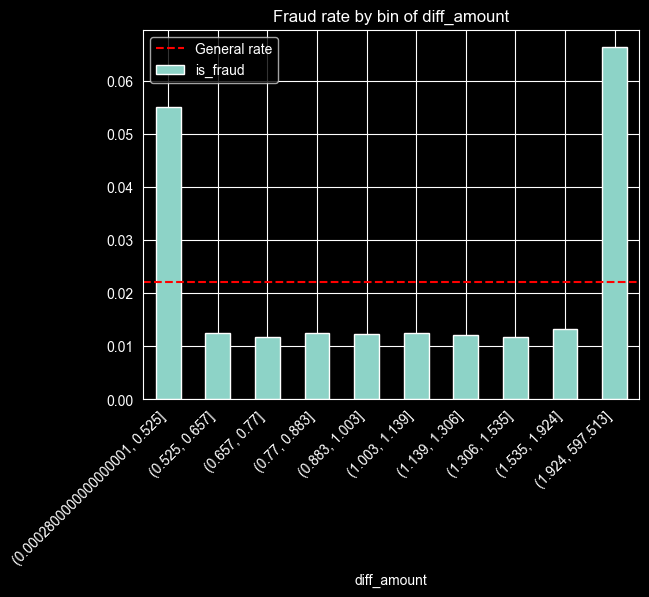

In [32]:
for feature in continuous_features:
    bins = pd.qcut(df_analysis[feature], q=10, duplicates='drop')
    rate = df_analysis.groupby(bins, observed=True)[target].mean()
    rate.plot(kind='bar', title=f'Fraud rate by bin of {feature}')
    plt.axhline(general_rate, color='red', linestyle='--', label='General rate')
    plt.xticks(rotation=45, ha='right')
    plt.legend()
    plt.show()

Insights:

Frauds happen more in newer accounts


As fraudes costumam apresentar ausência de verificação de segurança na transação, como 3D Secure, avs_match e CVV

**Temporal analysis (UTC (+00:00)))**

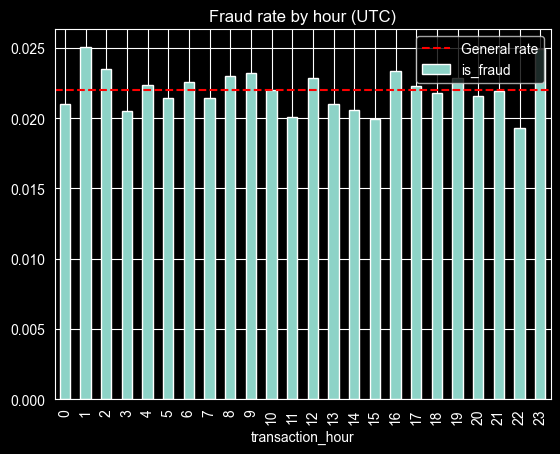

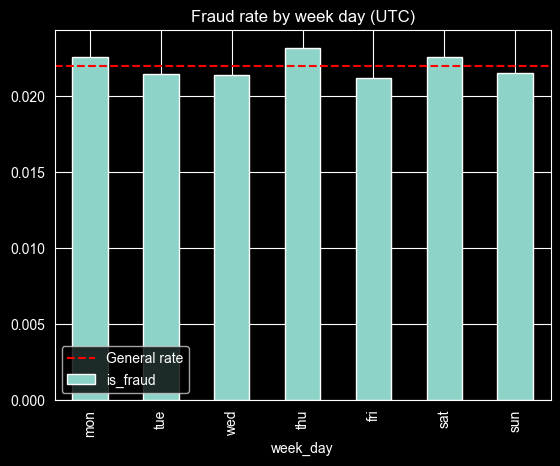

In [33]:
week_day_names = {0:'mon',1:'tue',2:'wed',3:'thu',4:'fri',5:'sat',6:'sun'}

rate_hour = df_analysis.groupby('transaction_hour')[target].mean()
rate_hour.plot(kind='bar', title='Fraud rate by hour (UTC)')
plt.axhline(general_rate, color='red', linestyle='--', label='General rate')
plt.legend()
plt.show()

rate_day = df_analysis.groupby('week_day')[target].mean().rename(week_day_names)
rate_day.plot(kind='bar', title='Fraud rate by week day (UTC)')
plt.axhline(general_rate, color='red', linestyle='--', label='General rate')
plt.legend()
plt.show()

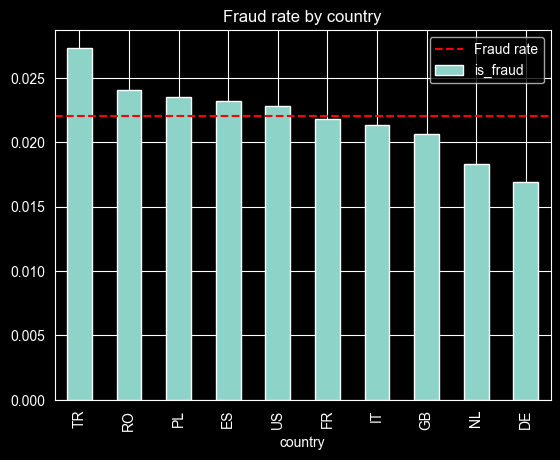

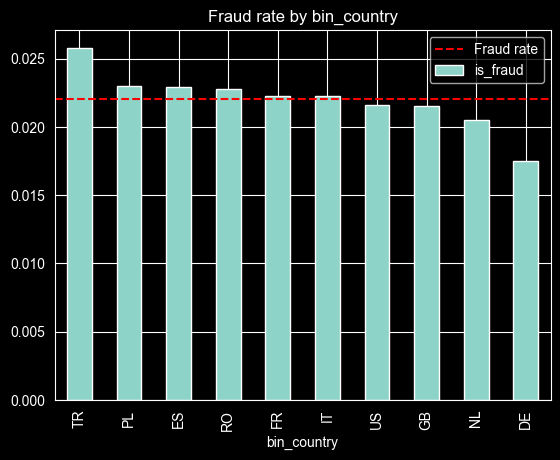

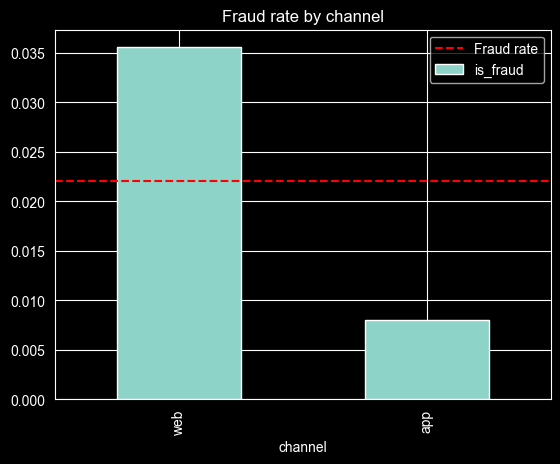

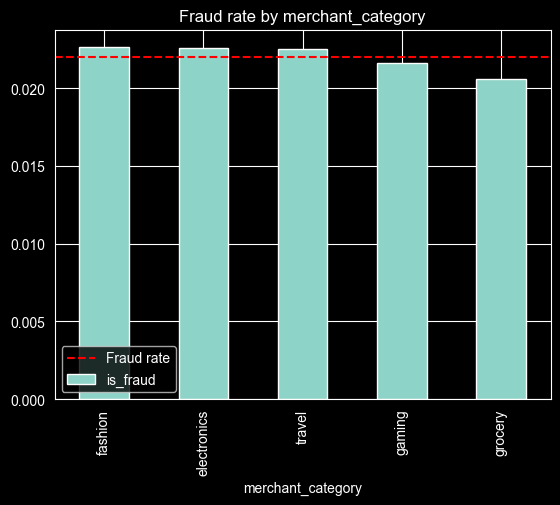

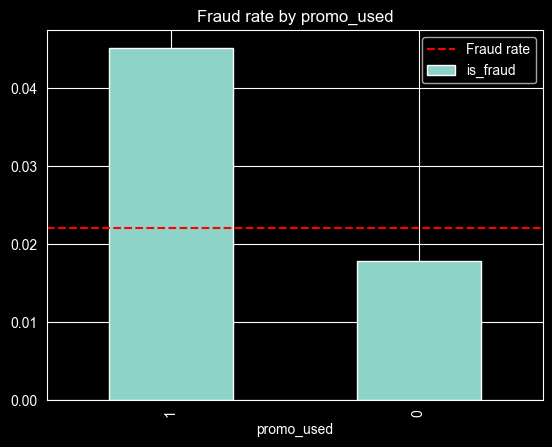

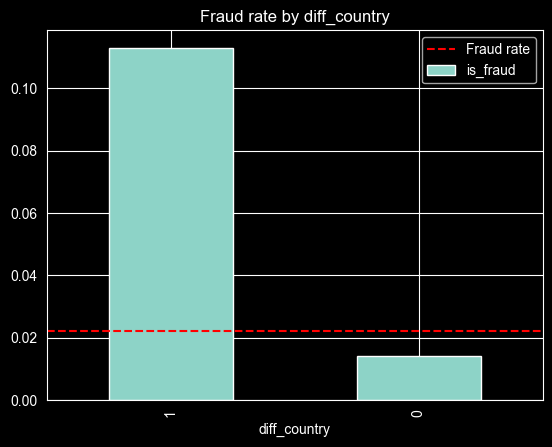

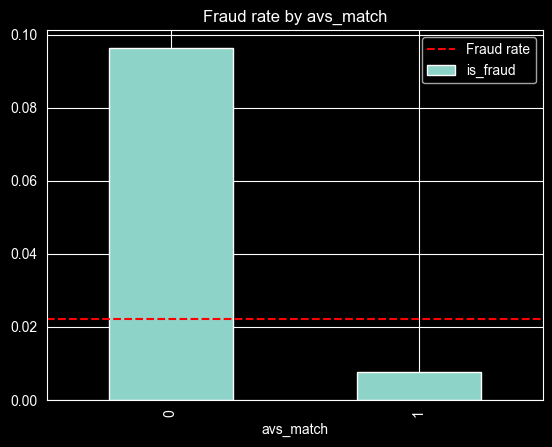

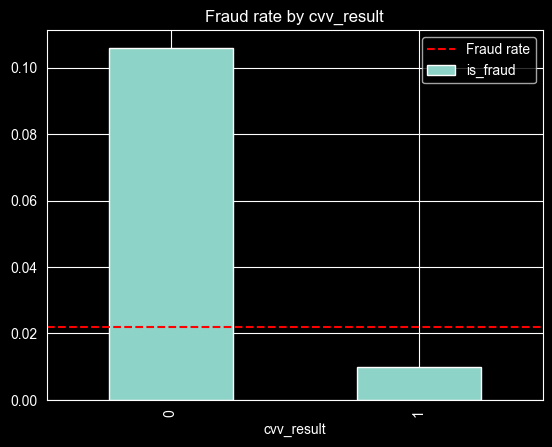

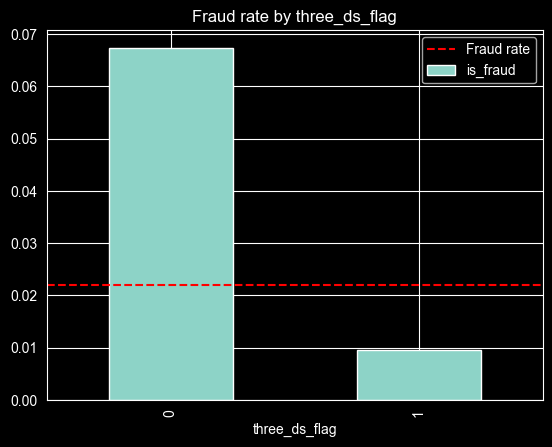

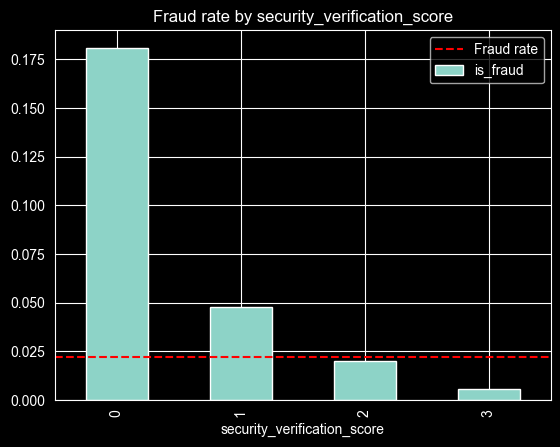

In [34]:
for feature in cat_features + binaries_features:
        rate_cat = df_analysis.groupby(feature)[target].mean().sort_values(ascending=0)
        rate_cat.plot(kind='bar', title=f'Fraud rate by {feature}')
        plt.axhline(general_rate, color='red', linestyle='--', label='Fraud rate')
        plt.legend()
        plt.show()

Insight:

Fraudes acontecem mais no canal "web"

**Analisando lift**

In [35]:
general_rate = df_analysis[target].mean()
features_lift = cat_features + binaries_features + time_features

tables = []
for feature in features_lift:
    table = df_analysis.groupby(feature)[target].agg(qtd='count', fraud_rate='mean')
    table['lift'] = table['fraud_rate'] / general_rate
    tables.append(table)

lift = pd.concat(tables, keys=features_lift, names=['feature', 'category'])
lift.sort_values('lift', ascending=False)

,,qtd,fraud_rate,lift
feature,category,,,
security_verification_score,0,14769,0.180852,8.216521
diff_country,1,18760,0.112953,5.131724
cvv_result,0,30281,0.105974,4.814649
avs_match,0,38415,0.096421,4.380617
three_ds_flag,0,51086,0.067396,3.061965
...,...,...,...,...
cvv_result,1,207103,0.009734,0.442251
three_ds_flag,1,186298,0.009565,0.434575
channel,app,116866,0.008035,0.365042


In [36]:
summary = df_analysis.select_dtypes(include='number').groupby(by=target).agg(['mean','median']).T
ratio = summary[1] / summary[0]
summary['ratio'] = ratio.where(np.isfinite(ratio) & (ratio > 0))
summary['strength'] = np.log(summary['ratio']).abs()
summary['times'] = np.where(summary['ratio'] >= 1, summary['ratio'], -1 / summary['ratio'])
summary.sort_values('strength', ascending=False)

,is_fraud,0,1,ratio,strength,times
diff_amount,mean,1.135087,9.182109,8.089341,2.090547,8.089341
diff_country,mean,0.071679,0.405550,5.657841,1.733042,5.657841
account_age_days,median,986.000000,222.000000,0.225152,1.490979,-4.441441
amount,mean,167.595096,577.730679,3.447181,1.237557,3.447181
shipping_distance_km,mean,339.658418,1125.491684,3.313599,1.198035,3.313599
avs_match,mean,0.850486,0.291100,0.342275,1.072140,-2.921624
security_verification_score,mean,2.528659,1.017990,0.402581,0.909859,-2.483972
three_ds_flag,mean,0.794783,0.341053,0.429114,0.846032,-2.330382
shipping_distance_km,median,269.490000,627.410000,2.328138,0.845069,2.328138
cvv_result,mean,0.883390,0.385837,0.436769,0.828351,-2.289541


**Pearson correlation between features**

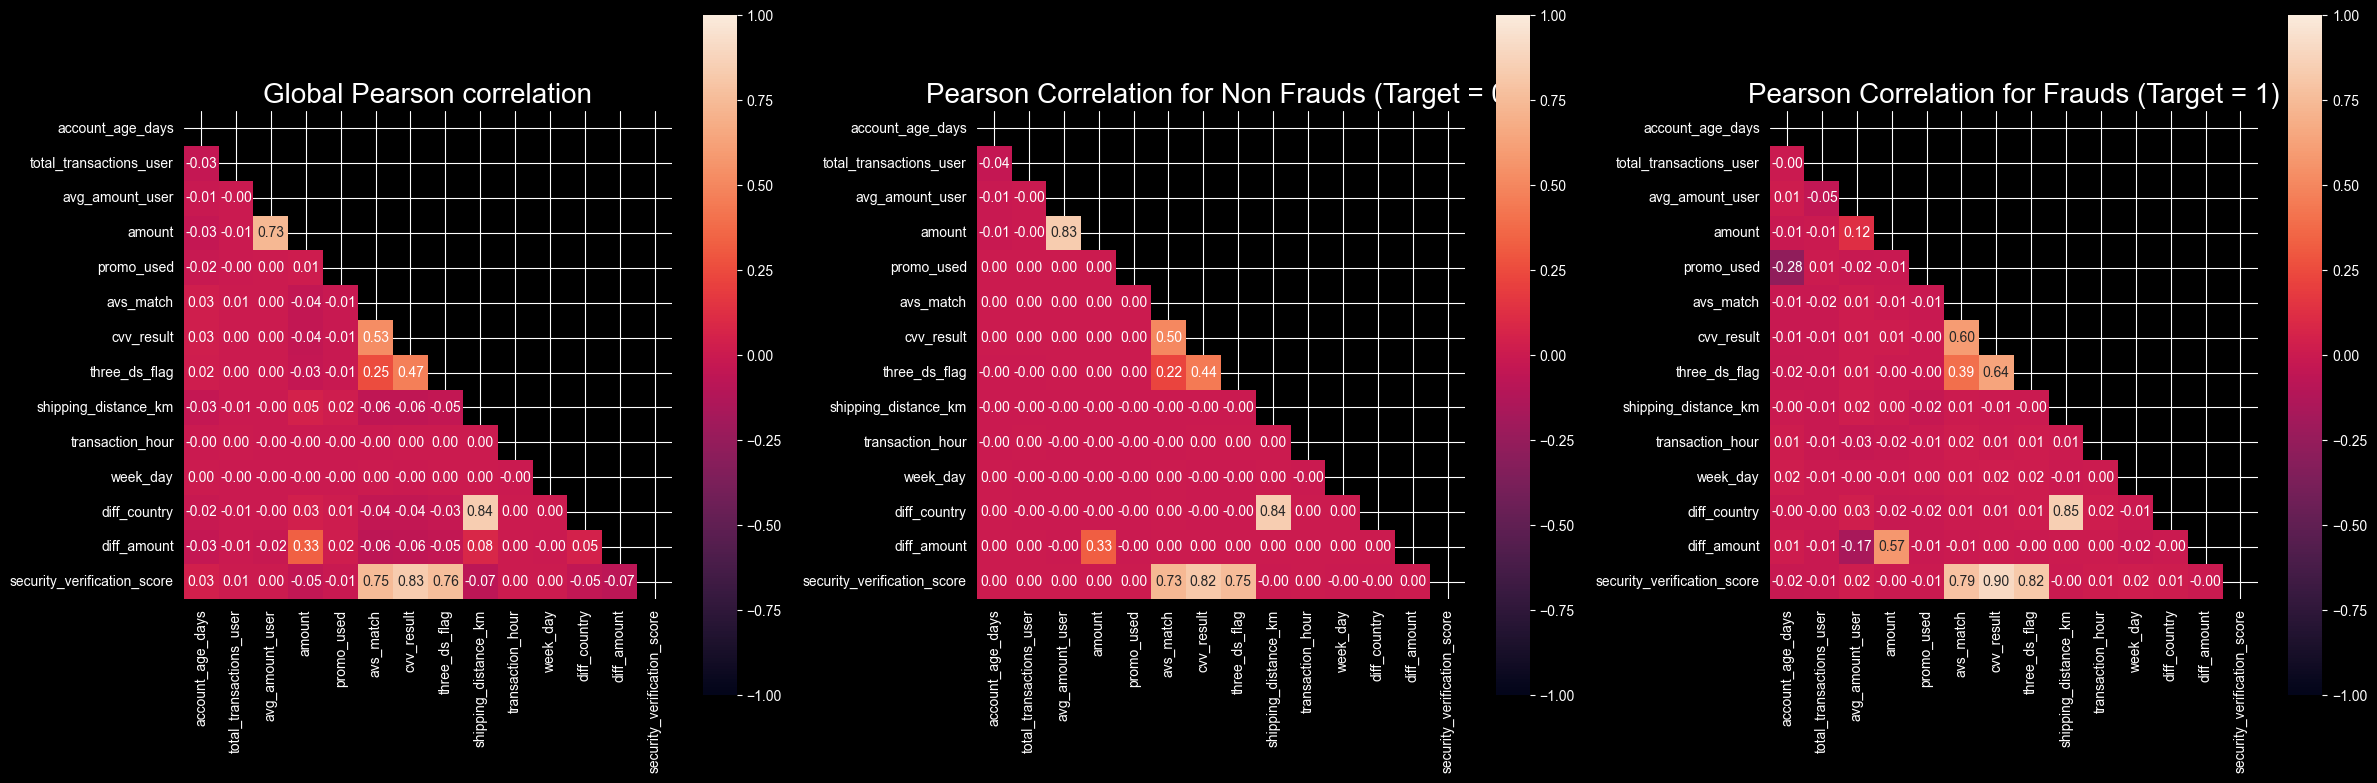

In [37]:
corr_global = df_analysis[num_features].corr()
corr_0 = df_analysis[df_analysis[target] == 0][num_features].corr()
corr_1 = df_analysis[df_analysis[target] == 1][num_features].corr()

fig , axes = plt.subplots(1, 3, figsize=(24, 8))

mask = np.triu(np.ones_like(df_analysis[num_features].corr(), dtype=bool))

sns.heatmap(corr_global, mask=mask, square=True, vmin=-1, vmax=1, annot=True, ax=axes[0], fmt='.2f')
axes[0].set_title("Global Pearson correlation", fontsize=20)

sns.heatmap(corr_0, mask=mask, square=True, vmin=-1, vmax=1, annot=True, ax=axes[1], fmt='.2f')
axes[1].set_title("Pearson Correlation for Non Frauds (Target = 0)", fontsize=20)

sns.heatmap(corr_1, mask=mask, square=True, vmin=-1, vmax=1, annot=True, ax=axes[2], fmt='.2f')
axes[2].set_title("Pearson Correlation for Frauds (Target = 1)", fontsize=20)

plt.tight_layout()
plt.show()

**Spearman correlation between features**

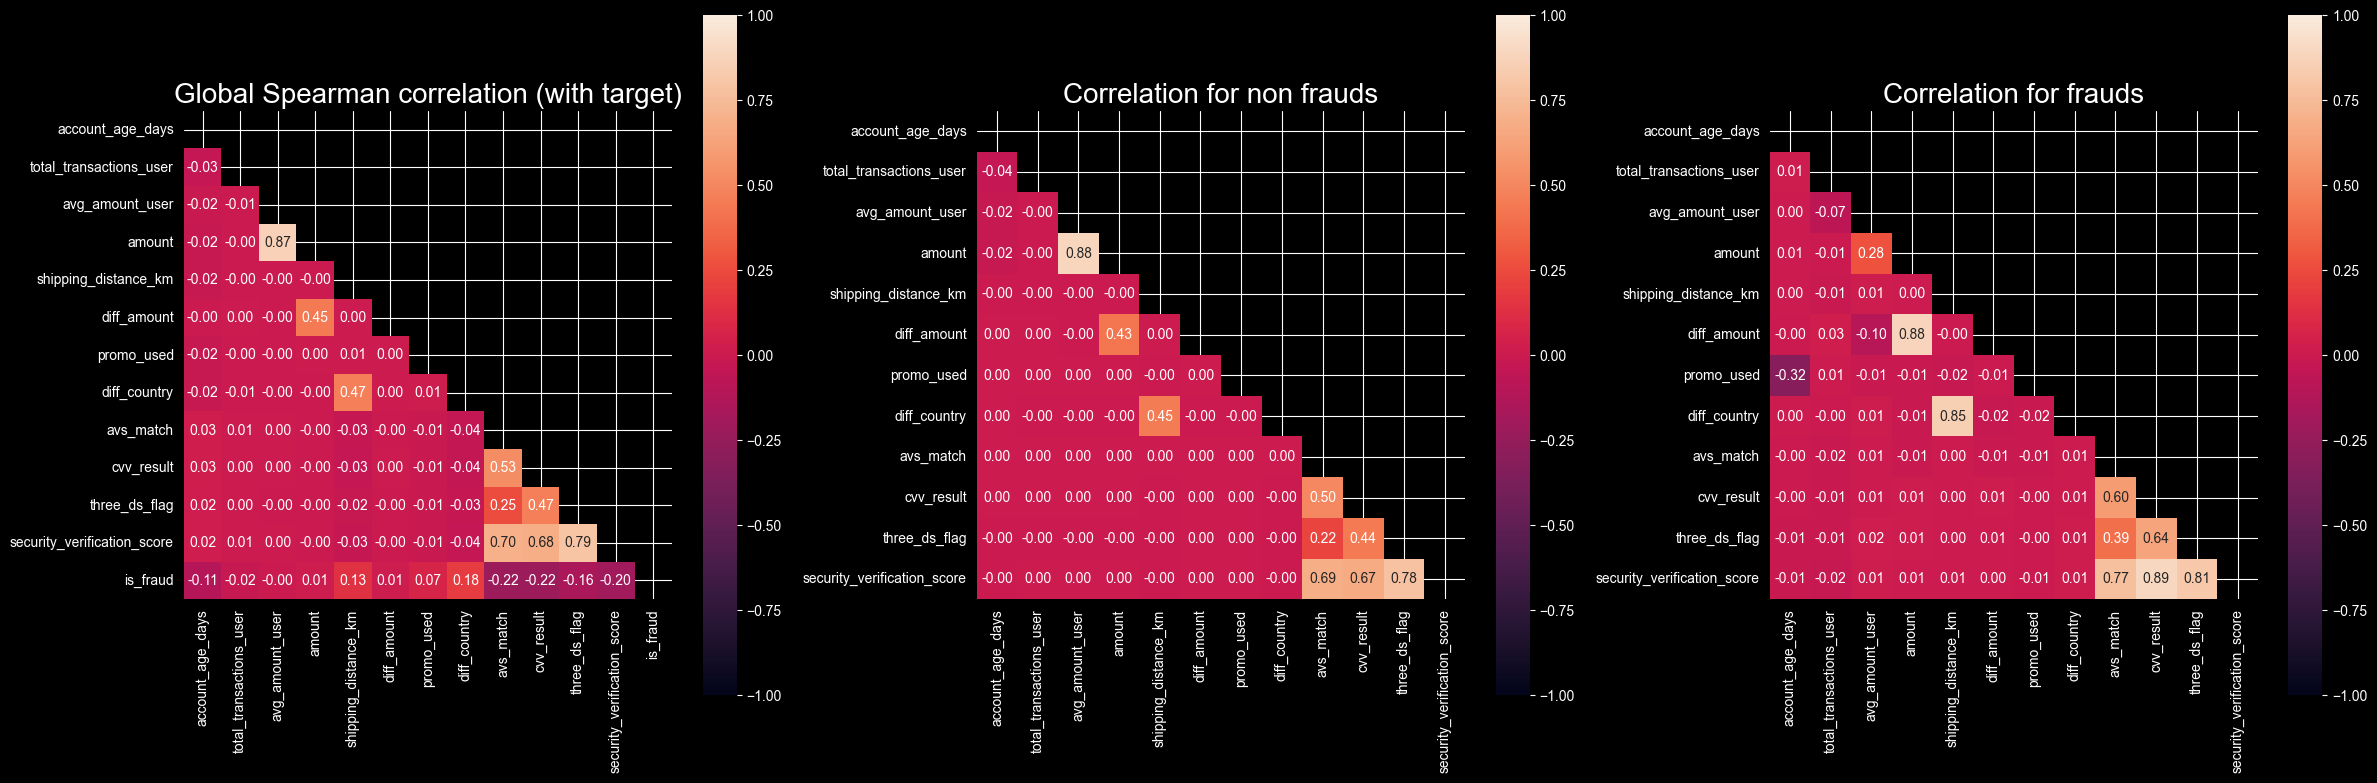

In [38]:
cols = continuous_features + binaries_features

corr_global = df_analysis[cols + [target]].corr(method='spearman')
corr_0 = df_analysis[df_analysis[target] == 0][cols].corr(method='spearman')
corr_1 = df_analysis[df_analysis[target] == 1][cols].corr(method='spearman')

mask_global = np.triu(np.ones_like(corr_global, dtype=bool))
mask = np.triu(np.ones_like(corr_0, dtype=bool))

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

sns.heatmap(corr_global, mask=mask_global, square=True, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=axes[0])
axes[0].set_title('Global Spearman correlation (with target)', fontsize=20)

sns.heatmap(corr_0, mask=mask, square=True, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=axes[1])
axes[1].set_title('Correlation for non frauds', fontsize=20)

sns.heatmap(corr_1, mask=mask, square=True, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=axes[2])
axes[2].set_title('Correlation for frauds', fontsize=20)

plt.tight_layout()
plt.show()

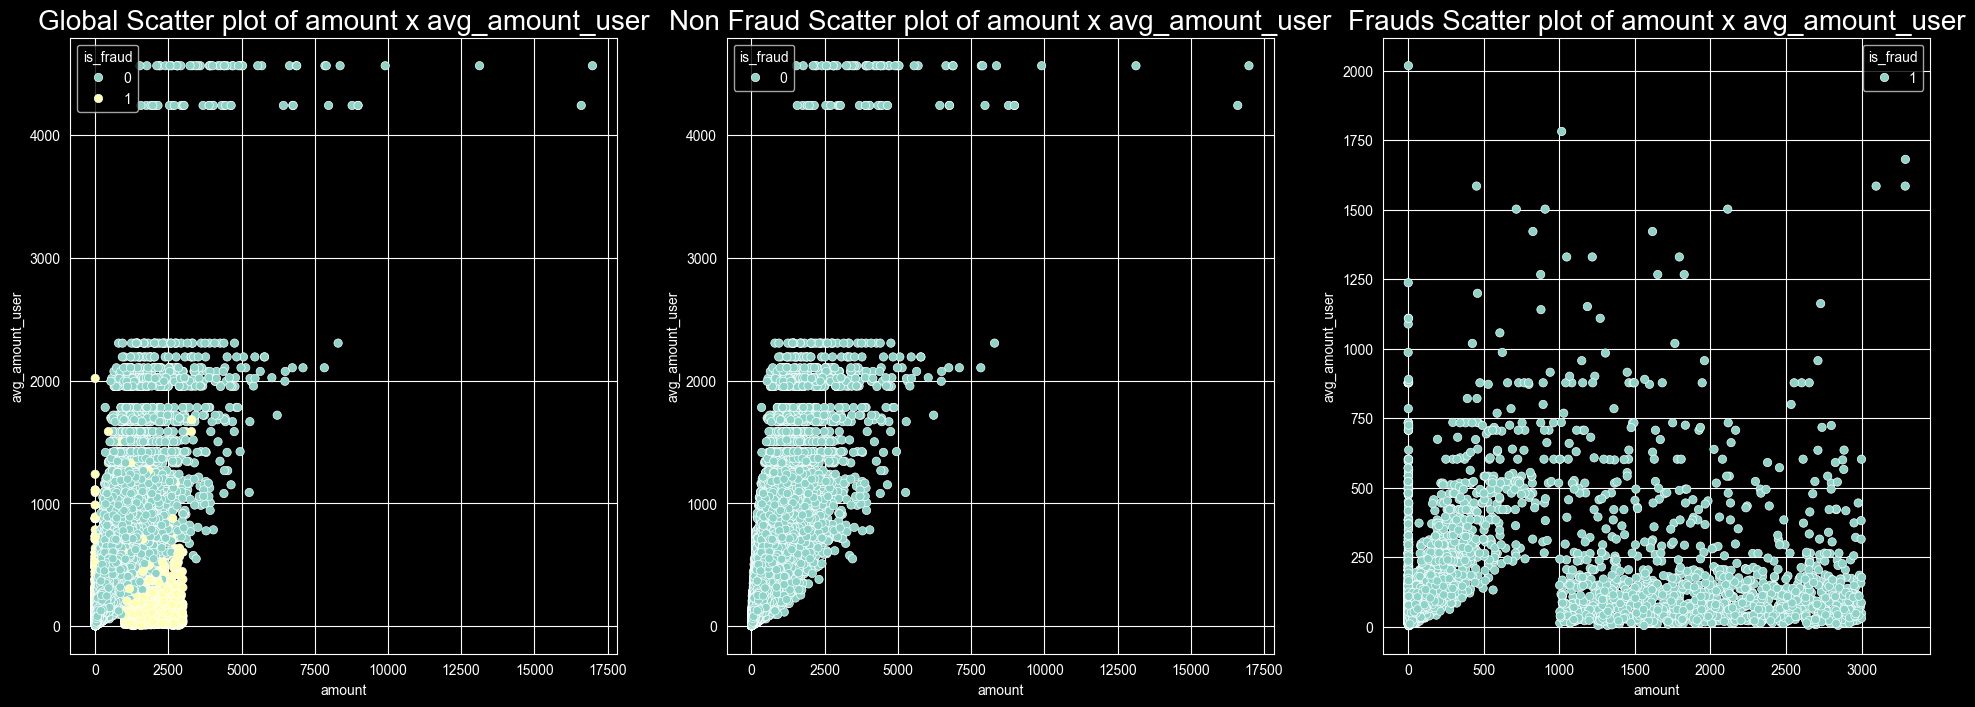

In [39]:
fig, axes = plt.subplots(1,3, figsize=(24, 8))
sns.scatterplot(data=df_analysis, x='amount', y="avg_amount_user", hue=target, ax=axes[0])
axes[0].set_title("Global Scatter plot of amount x avg_amount_user", fontsize=20)

sns.scatterplot(data=df_analysis[df_analysis[target] == 0], x='amount', y="avg_amount_user",hue=target, ax=axes[1])
axes[1].set_title("Non Fraud Scatter plot of amount x avg_amount_user", fontsize=20)

sns.scatterplot(data=df_analysis[df_analysis[target] == 1], x='amount', y="avg_amount_user",hue=target, ax=axes[2])
axes[2].set_title("Frauds Scatter plot of amount x avg_amount_user", fontsize=20)

plt.show()

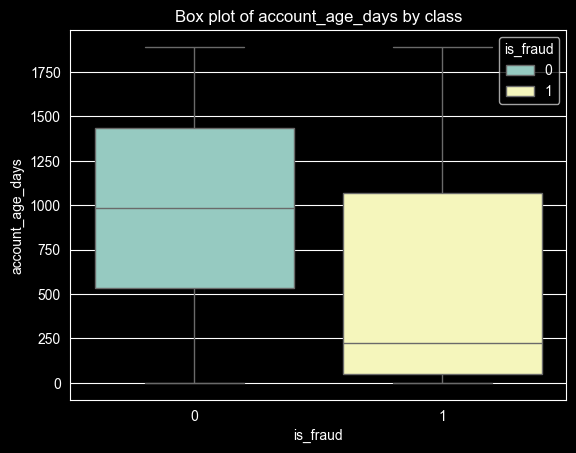

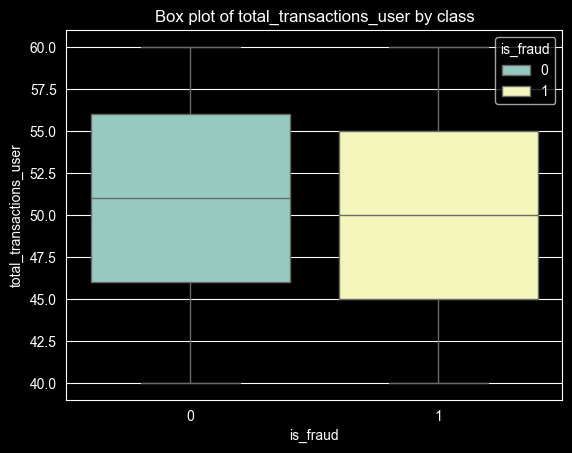

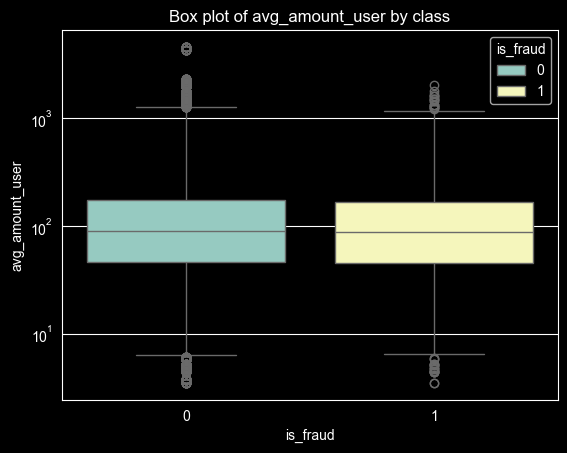

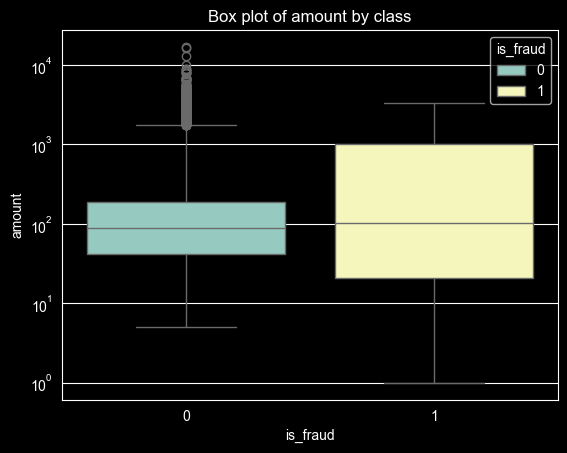

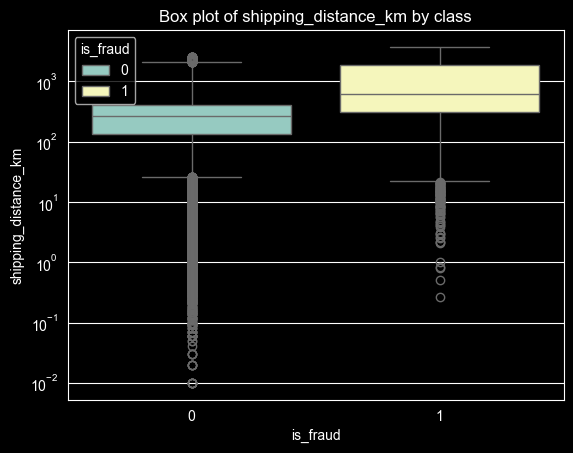

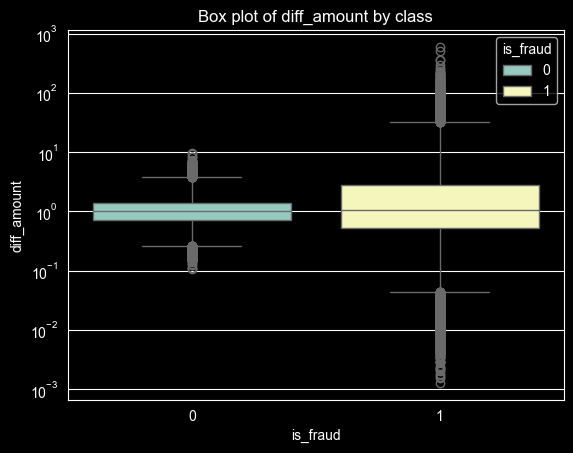

In [40]:
for feature in continuous_features:
    sns.boxplot(data=df_analysis, x=target, y=feature, hue=target, log_scale=(feature in log_features))
    plt.title(f'Box plot of {feature} by class')
    plt.show()

In [41]:
cortes = {
    'account_age_days':     [0, 90, np.inf],
    'amount':               [0, 5, 1000, 1500, np.inf],
    'shipping_distance_km': [0, 500, 750, np.inf],
    'diff_amount':          [0, 0.2, 5, np.inf],
    'security_verification_score': [-0.5, 0.5, 1.5, 2.5, 3.5]
}

for feature, corte in cortes.items():
    faixas = pd.cut(df_analysis[feature], corte, include_lowest=True)
    t = df_analysis.groupby(faixas, observed=True)[target].agg(qtd='count', fraudes='sum', fraud_rate='mean')
    t['pct_fraudes'] = t['fraudes'] / t['fraudes'].sum()
    t['lift'] = t['fraud_rate'] / general_rate
    print(feature)
    display(t.round(3))

account_age_days


,qtd,fraudes,fraud_rate,pct_fraudes,lift
account_age_days,,,,,
"(-0.001, 90.0]",5001,2440,0.488,0.467,22.167
"(90.0, inf]",232383,2785,0.012,0.533,0.544


amount


,qtd,fraudes,fraud_rate,pct_fraudes,lift
amount,,,,,
"(-0.001, 5.0]",2208,1034,0.468,0.198,21.276
"(5.0, 1000.0]",230285,2870,0.012,0.549,0.566
"(1000.0, 1500.0]",2548,357,0.140,0.068,6.366
"(1500.0, inf]",2343,964,0.411,0.184,18.693


shipping_distance_km


,qtd,fraudes,fraud_rate,pct_fraudes,lift
shipping_distance_km,,,,,
"(-0.001, 500.0]",217593,2074,0.010,0.397,0.433
"(500.0, 750.0]",3112,1032,0.332,0.198,15.066
"(750.0, inf]",16679,2119,0.127,0.406,5.772


diff_amount


,qtd,fraudes,fraud_rate,pct_fraudes,lift
diff_amount,,,,,
"(-0.001, 0.2]",1107,972,0.878,0.186,39.892
"(0.2, 5.0]",234980,3095,0.013,0.592,0.598
"(5.0, inf]",1297,1158,0.893,0.222,40.563


security_verification_score


,qtd,fraudes,fraud_rate,pct_fraudes,lift
security_verification_score,,,,,
"(-0.501, 0.5]",14769,2671,0.181,0.511,8.217
"(0.5, 1.5]",15163,721,0.048,0.138,2.160
"(1.5, 2.5]",45149,901,0.020,0.172,0.907
"(2.5, 3.5]",162303,932,0.006,0.178,0.261


**Conclusions**
-
*(training set: ~237k transactions, 2.2% fraud)*


1. New accounts: accounts up to 90 days old concentrate about half of all frauds, and roughly 1 in 2 of their transactions is fraudulent. After 90 days, the fraud rate drops to ~1.2%.

2. Security checks: the fraud rate falls with every check passed (AVS, CVV and 3-D Secure). Transactions that passed none have an 18% fraud rate (8x the average) and account for about half of all frauds, despite being only 6% of transactions. Those that passed all three have a 0.6% fraud rate, yet still hold ~18% of frauds, so checks alone are not enough to stop fraud.

3. Country mismatch: when the card’s issuing country differs from the transaction country, the fraud rate is ~11%, versus ~1.4% when they match (lift ~5).

4. U-shaped amount: purchases up to 5 (likely card testing) have a 47% fraud rate and those above 1,500 have 41%. Between 5 and 1,000 the rate stays around 1%, and it already rises to 14% between 1,000 and 1,500.

5. Out of the customer’s pattern: purchases far below or far above the customer’s own average spend are almost all fraudulent.

6. Shipping distance: up to 500 km, the fraud rate is ~1%; between 500 and 750 km, it jumps to ~33%.

7. Channel: web transactions show about 4 times more fraud than app transactions.

8. No signal: merchant category, the customer’s total number of transactions and the customer’s average spend do not distinguish fraud from legitimate transactions.

*Note: the clean cut-offs at round numbers and the near-constant rate outside them suggest the dataset is synthetic. Real-world data would be noisier, so these findings should be read as risk signals, not as fixed rules.*